# فاز ۱ — شناخت مطالعه، داده و آمار توصیفی
**پروژه‌ی درس آمار و کاربردها — پاییز ۱۴۰۵**
**مسیر الف: NHANES 2021–2023**

این نوت‌بوک تسک‌های مشترک (۱ تا ۱۰) و تسک‌های ویژه‌ی مسیر الف (الف۱ تا الف۴) فاز اول را
پیاده‌سازی می‌کند. منطق اصلی پاک‌سازی و ادغام داده در `src/analysis.py` نوشته شده تا
هم این نوت‌بوک و هم اسکریپت تولید گزارش PDF (`reports/phase1.pdf`) از یک منبع واحد
استفاده کنند و دو خروجی ناسازگار نباشند.


In [1]:

import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import analysis as A

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110
FIG_DIR = "../figures"


## ۱. منشأ داده و سازوکار جمع‌آوری

**منبع رسمی:** پیمایش ملی سلامت و تغذیه‌ی ایالات متحده (**NHANES**)، که توسط
مرکز ملی آمار سلامت (NCHS) زیرمجموعه‌ی CDC اجرا می‌شود.

**دوره‌ی مصرفی این پروژه:** چرخه‌ی آگوست ۲۰۲۱ تا آگوست ۲۰۲۳ (`_L`). این چرخه یک
چرخه‌ی **ترکیبی و استثنایی** است: به‌دلیل وقفه در جمع‌آوری داده در دوران همه‌گیری
کرونا (نیمه‌ی ۲۰۲۰ تعلیق شد)، NCHS داده‌های دو سال ۲۰۲۱ و ۲۰۲۲–۲۰۲۳ را با هم
ترکیب و به‌عنوان یک انتشار ملیِ نماینده منتشر کرده است؛ به همین دلیل وزن‌های
نمونه‌گیری این دوره (`WTMEC2YR`, `WTINT2YR`) از همان ابتدا برای یک دوره‌ی دوساله
محاسبه شده‌اند و نیازی به تقسیم اضافه ندارند.

**سازوکار جمع‌آوری:** NHANES یک طرح دومرحله‌ای دارد:
1. **مصاحبه‌ی خانگی (Household Interview):** پرسشنامه‌های جمعیت‌شناختی، سبک زندگی
   (خواب، فعالیت بدنی، مصرف دخانیات) و سلامت.
2. **معاینه‌ی فیزیکی در مرکز سیار معاینه (Mobile Examination Center – MEC):**
   اندازه‌گیری‌های بدنی (قد، وزن، BMI) و فشارخون توسط پرسنل آموزش‌دیده با
   دستگاه نوسان‌سنج (oscillometric) انجام می‌شود.

**محدودیت دسترسی:** داده‌ها کاملاً عمومی و بدون نیاز به مجوز خاص از پایگاه
CDC قابل دانلود هستند؛ فقط فایل‌های حساس‌تر (مثلاً داده‌های ژنتیکی یا محل
جغرافیایی دقیق) به‌صورت محدودشده (restricted-use) در دسترس پژوهشگران تأییدشده
قرار دارند که در این پروژه استفاده نشده‌اند.


In [2]:

files_used = {
    "DEMO_L": "Demographics & sample weights (base file)",
    "BPXO_L": "Blood Pressure - Oscillometric Measurements",
    "BMX_L":  "Body Measures (height, weight, BMI, waist)",
    "SLQ_L":  "Sleep Disorders questionnaire",
    "PAQ_L":  "Physical Activity questionnaire",
    "SMQ_L":  "Smoking - Cigarette Use questionnaire",
}
for k, v in files_used.items():
    print(f"{k:8s} : {v}")


DEMO_L   : Demographics & sample weights (base file)
BPXO_L   : Blood Pressure - Oscillometric Measurements
BMX_L    : Body Measures (height, weight, BMI, waist)
SLQ_L    : Sleep Disorders questionnaire
PAQ_L    : Physical Activity questionnaire
SMQ_L    : Smoking - Cigarette Use questionnaire


## ۲. واحد مشاهده و ساختار داده

**واحد مشاهده:** هر ردیف یک **فرد پاسخ‌دهنده** در پیمایش NHANES است، که با شناسه‌ی
یکتای `SEQN` در تمام فایل‌های اجزای پیمایش قابل شناسایی و ادغام است.

**ساختار:** داده به‌صورت **wide** است — هر فرد یک ردیف دارد و متغیرهای مختلف
(جمعیت‌شناختی، فشارخون، تن‌سنجی، خواب، فعالیت، دخانیات) در ستون‌های جداگانه از
شش فایل مجزا نگه‌داری می‌شوند که باید روی `SEQN` ادغام (merge) شوند. هیچ
سلسله‌مراتب تکرارشونده‌ای (مثل چند بازدید برای هر فرد) در این زیرمجموعه وجود
ندارد؛ برای فشارخون سه بار اندازه‌گیری تکراری **درون همان ردیف** (`BPXOSY1..3`)
ثبت شده که میانگین آن‌ها متغیر اصلی پاسخ ما را می‌سازد.


In [3]:

analytic, counts = A.merge_and_clean()
print("ردیف پایه (DEMO_L):", counts["n_demo_base"])
print("ردیف پس از ادغام همه‌ی فایل‌ها (هنوز بدون فیلتر):", counts["n_merged_total"])
print("تعداد SEQN تکراری:", counts["duplicate_seqn"])
analytic.head()


ردیف پایه (DEMO_L): 11933
ردیف پس از ادغام همه‌ی فایل‌ها (هنوز بدون فیلتر): 11933
تعداد SEQN تکراری: 0


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,DMQMILIZ,DMDBORN4,DMDYRUSR,DMDEDUC2,DMDMARTZ,RIDEXPRG,DMDHHSIZ,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,...,PAD800,PAD810Q,PAD810U,PAD820,PAD680,SMQ020,SMQ040,SMD641,SMD650,SMD100MN,SMQ621,SMD630,SMAQUEX2,sbp_mean,dbp_mean,n_bp_readings,sex,age_years,sleep_hours,sedentary_min,bmi,smoking_status,smoker_group,education,age_group
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,2.0,2.0,6.0,5.0,1.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,...,45.0,3.000000e+00,b'W',45.0,360.0,1.0,3.0,NaN,NaN,NaN,NaN,NaN,1.0,132.666667,96.000000,3,Male,43.0,9.5,360.0,27.0,Former smoker,Non-current smoker,College grad+,40-59
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,2.0,1.0,NaN,5.0,1.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,...,45.0,3.000000e+00,b'W',45.0,480.0,1.0,3.0,NaN,NaN,NaN,NaN,NaN,1.0,117.000000,78.666667,3,Male,66.0,9.0,480.0,33.5,Former smoker,Non-current smoker,College grad+,60+
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,2.0,2.0,6.0,3.0,1.0,2.0,7.0,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,...,20.0,5.397605e-79,b'',NaN,240.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,109.000000,78.333333,3,Female,44.0,8.0,240.0,29.7,Never smoker,Non-current smoker,HS grad/GED,40-59
8,130386.0,12.0,2.0,1.0,34.0,NaN,1.0,1.0,1.0,NaN,2.0,1.0,NaN,4.0,1.0,NaN,3.0,NaN,NaN,NaN,NaN,NaN,30995.282610,39988.452940,179.0,...,30.0,1.000000e+00,b'M',30.0,180.0,1.0,3.0,NaN,NaN,NaN,NaN,NaN,1.0,115.000000,73.666667,3,Male,34.0,7.5,180.0,30.2,Former smoker,Non-current smoker,Some college/AA,20-39
9,130387.0,12.0,2.0,2.0,68.0,NaN,3.0,3.0,2.0,NaN,2.0,1.0,NaN,5.0,3.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,19896.970559,20776.254850,181.0,...,NaN,5.397605e-79,b'',NaN,1200.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,141.333333,76.000000,3,Female,68.0,3.0,1200.0,42.6,Never smoker,Non-current smoker,College grad+,60+


## ۳. نمونه‌گیری، قابلیت تعمیم و جمعیت تحت پوشش

NHANES از یک طرح نمونه‌گیری **پیچیده‌ی چندمرحله‌ای، طبقه‌بندی‌شده و خوشه‌ای**
استفاده می‌کند (نه نمونه‌گیری تصادفی ساده)، با **اضافه‌نمونه‌گیری عمدی** از
گروه‌های خاص (مثلاً گروه‌های سنی بالا، اقلیت‌های نژادی/قومی خاص، افراد
کم‌درآمد) تا برآوردهای دقیق‌تری برای آن زیرگروه‌ها به‌دست آید.

این مطالعه یک **مطالعه‌ی مشاهده‌ای مقطعی (observational cross-sectional)** است،
نه آزمایش تصادفی؛ بنابراین نمونه‌گیری تصادفی **از جمعیت** است (نه تخصیص تصادفی
به گروه‌های درمان).

به همین دلیل، افراد موجود در فایل **نماینده‌ی برابر جمعیت نیستند** — افراد
اضافه‌نمونه‌گیری‌شده باید وزن کمتری، و بقیه وزن بیشتری در برآورد جمعیتی داشته
باشند؛ این دقیقاً همان نقشی است که وزن‌های `WTMEC2YR`/`WTINT2YR` ایفا می‌کنند
(جزئیات در بخش الف۲ و الف۳).

نتایج وزن‌دار این زیرمجموعه (پس از اعمال معیارهای ورود، بخش الف۴) قابل تعمیم
به **جمعیت غیرنهادی (noninstitutionalized) ۲۰ سال به بالای آمریکا در بازه‌ی
۲۰۲۱–۲۰۲۳** است، نه به کل جهان یا به زیرگروه‌های نهادی (مثل ساکنان زندان‌ها یا
مراکز نگهداری طولانی‌مدت) که اساساً در چارچوب نمونه‌گیری NHANES نیستند.


## ۴. طبقه‌بندی متغیرهای اصلی

| متغیر | توضیح | نوع | مقیاس |
|---|---|---|---|
| `sbp_mean` | میانگین فشارخون سیستولیک (۳ خوانش) | کمّی، پیوسته | نسبی (ratio) |
| `dbp_mean` | میانگین فشارخون دیاستولیک | کمّی، پیوسته | نسبی |
| `bmi` | شاخص توده‌ی بدنی | کمّی، پیوسته | نسبی |
| `sleep_hours` | ساعات معمول خواب در روزهای کاری | کمّی، پیوسته (در عمل گسسته‌ی ریزدانه) | نسبی |
| `sedentary_min` | دقایق بی‌تحرکی روزانه | کمّی، پیوسته | نسبی |
| `age_years` | سن به سال | کمّی، گسسته | نسبی |
| `age_group` | گروه سنی (۲۰–۳۹ / ۴۰–۵۹ / ۶۰+) | کیفی | ترتیبی |
| `sex` | جنسیت | کیفی | اسمی (دوحالته) |
| `education` | سطح تحصیلات | کیفی | ترتیبی |
| `smoking_status` | وضعیت مصرف دخانیات (۴ سطح) | کیفی | اسمی |
| `smoker_group` | سیگاری فعلی / غیر | کیفی | اسمی (دوحالته) |


In [4]:

var_cols = ["sbp_mean","dbp_mean","bmi","sleep_hours","sedentary_min",
            "age_years","age_group","sex","education","smoking_status","smoker_group"]
analytic[var_cols].dtypes


sbp_mean           float64
dbp_mean           float64
bmi                float64
sleep_hours        float64
sedentary_min      float64
age_years          float64
age_group         category
sex                 object
education           object
smoking_status      object
smoker_group        object
dtype: object

## ۵. ممیزی کیفیت داده

برای متغیرهای اصلی، درصد مقادیر گم‌شده و مقادیر غیرممکن را بررسی می‌کنیم.
کدهای ویژه‌ی «امتناع» (۷) و «نمی‌دانم» (۹، یا معادل‌های سه/چهاررقمی آن‌ها در
`PAD680`, `SMQ040`, `SMQ020`, `DMDEDUC2`) پیش از این در `analysis.py` به مقدار
گم‌شده (NaN) تبدیل شده‌اند — چون این کدها مقدار واقعی متغیر نیستند و نگه‌داشتن
آن‌ها به‌عنوان عدد، میانگین‌ها را به‌شدت منحرف می‌کرد (مثلاً کد ۷۷۷۷ دقیقه
بی‌تحرکی). مقادیر گم‌شده حذف نشده‌اند؛ فقط به NaN تبدیل و در تحلیل نادیده
گرفته می‌شوند (`dropna` موضعی در هر محاسبه، نه حذف سراسری ردیف‌ها).


In [5]:

dq = A.data_quality_report(analytic, var_cols)
dq


,variable,n_missing,pct_missing,n_valid
0,sbp_mean,0,0.00,5824
1,dbp_mean,0,0.00,5824
2,bmi,58,1.00,5766
3,sleep_hours,59,1.01,5765
4,sedentary_min,42,0.72,5782
5,age_years,0,0.00,5824
6,age_group,0,0.00,5824
7,sex,0,0.00,5824
8,education,3,0.05,5821
9,smoking_status,7,0.12,5817


In [6]:

# بررسی مقادیر غیرممکن / دورافتاده‌ی آشکار
print("SBP خارج از بازه‌ی فیزیولوژیک قابل‌قبول (<70 یا >250):",
      ((analytic["sbp_mean"] < 70) | (analytic["sbp_mean"] > 250)).sum())
print("BMI خارج از بازه‌ی قابل‌قبول (<10 یا >80):",
      ((analytic["bmi"] < 10) | (analytic["bmi"] > 80)).sum())
print("ساعات خواب خارج از بازه‌ی منطقی (<2 یا >16):",
      ((analytic["sleep_hours"] < 2) | (analytic["sleep_hours"] > 16)).sum())
print("\nتصمیم: هیچ مقداری در این محدوده‌های آشکارا نامعقول یافت نشد؛")
print("بنابراین در فاز ۱ هیچ مشاهده‌ای صرفاً به‌دلیل دورافتادگی حذف نشده است.")


SBP خارج از بازه‌ی فیزیولوژیک قابل‌قبول (<70 یا >250): 0
BMI خارج از بازه‌ی قابل‌قبول (<10 یا >80): 0
ساعات خواب خارج از بازه‌ی منطقی (<2 یا >16): 0

تصمیم: هیچ مقداری در این محدوده‌های آشکارا نامعقول یافت نشد؛
بنابراین در فاز ۱ هیچ مشاهده‌ای صرفاً به‌دلیل دورافتادگی حذف نشده است.


## ۶. جدول‌های فراوانی و توزیع تجربی متغیرهای کیفی

In [7]:

for c in ["sex", "age_group", "education", "smoking_status"]:
    print(f"\n--- {c} ---")
    tab = analytic[c].astype("object").fillna("Missing").value_counts()
    pct = (100 * tab / len(analytic)).round(1)
    print(pd.DataFrame({"freq": tab, "pct": pct}))



--- sex ---
        freq   pct
sex               
Female  3178  54.6
Male    2646  45.4

--- age_group ---
           freq   pct
age_group            
60+        2691  46.2
40-59      1681  28.9
20-39      1452  24.9

--- education ---
                 freq   pct
education                  
College grad+    2079  35.7
Some college/AA  1771  30.4
HS grad/GED      1235  21.2
9-11th grade      457   7.8
<9th grade        279   4.8
Missing             3   0.1

--- smoking_status ---
                    freq   pct
smoking_status                
Never smoker        3396  58.3
Former smoker       1544  26.5
Current, every day   709  12.2
Current, some days   168   2.9
Missing                7   0.1


## ۷. مرکز و پراکندگی متغیرهای کمّی اصلی

In [8]:

A.center_spread_table(analytic, ["sbp_mean","dbp_mean","bmi","sleep_hours","sedentary_min","age_years"])


,variable,n,mean,sd,median,iqr,min,max
0,sbp_mean,5824,123.03,18.08,120.67,22.0,70.0,232.33
1,dbp_mean,5824,74.79,10.99,74.00,14.0,34.0,139.00
2,bmi,5766,29.73,7.15,28.40,8.8,11.1,68.90
3,sleep_hours,5765,7.70,1.58,8.00,1.5,2.0,14.00
4,sedentary_min,5782,365.58,210.38,300.00,300.0,0.0,1380.00
5,age_years,5824,54.09,17.04,58.00,28.0,20.0,80.00


## ۸. مصورسازی (حداقل ۴ نمودار دوبعدی و معنادار)

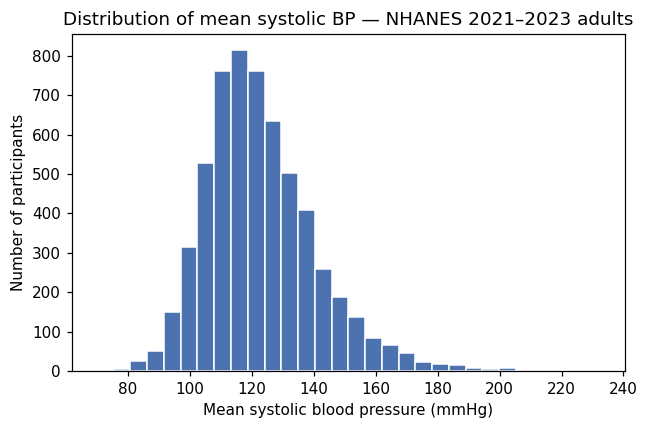

In [9]:

fig, ax = plt.subplots(figsize=(6,4))
ax.hist(analytic["sbp_mean"].dropna(), bins=30, color="#4C72B0", edgecolor="white")
ax.set_xlabel("Mean systolic blood pressure (mmHg)")
ax.set_ylabel("Number of participants")
ax.set_title("Distribution of mean systolic BP — NHANES 2021–2023 adults")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig1_hist_sbp.png", dpi=150)
plt.show()


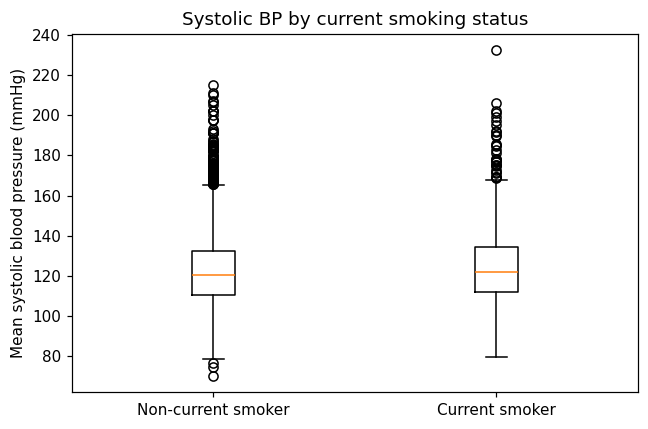

In [10]:

fig, ax = plt.subplots(figsize=(6,4))
groups = [analytic.loc[analytic["smoker_group"]==g, "sbp_mean"].dropna()
          for g in ["Non-current smoker","Current smoker"]]
ax.boxplot(groups, tick_labels=["Non-current smoker","Current smoker"])
ax.set_ylabel("Mean systolic blood pressure (mmHg)")
ax.set_title("Systolic BP by current smoking status")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig2_box_sbp_smoking.png", dpi=150)
plt.show()


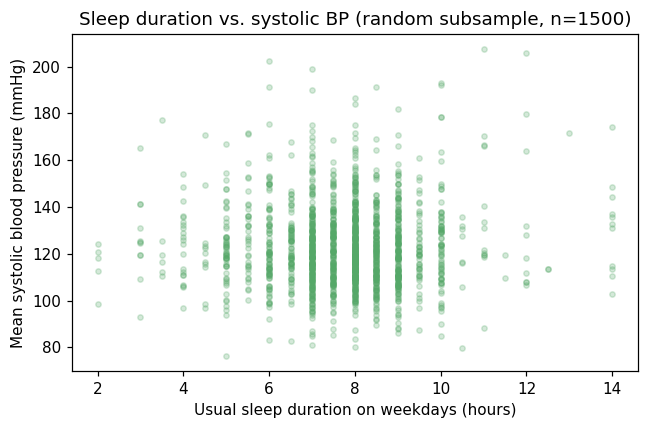

In [11]:

fig, ax = plt.subplots(figsize=(6,4))
sample = analytic.dropna(subset=["sleep_hours","sbp_mean"]).sample(
    n=min(1500, analytic.dropna(subset=["sleep_hours","sbp_mean"]).shape[0]), random_state=1)
ax.scatter(sample["sleep_hours"], sample["sbp_mean"], alpha=0.25, s=12, color="#55A868")
ax.set_xlabel("Usual sleep duration on weekdays (hours)")
ax.set_ylabel("Mean systolic blood pressure (mmHg)")
ax.set_title("Sleep duration vs. systolic BP (random subsample, n={})".format(len(sample)))
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig3_scatter_sleep_sbp.png", dpi=150)
plt.show()


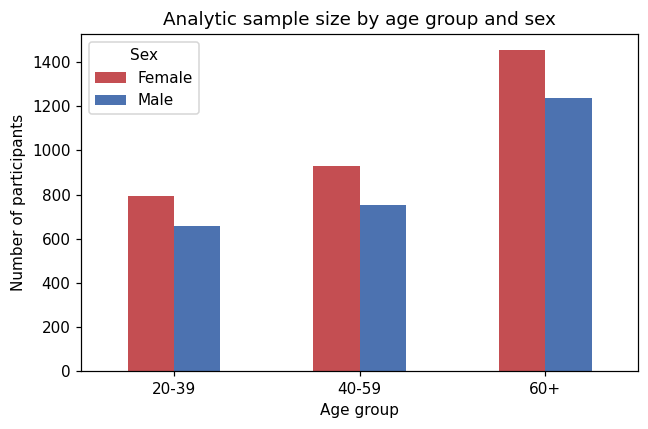

In [12]:

fig, ax = plt.subplots(figsize=(6,4))
counts_by_group = analytic.groupby(["age_group","sex"], observed=True).size().unstack()
counts_by_group.plot(kind="bar", ax=ax, color=["#C44E52","#4C72B0"])
ax.set_xlabel("Age group")
ax.set_ylabel("Number of participants")
ax.set_title("Analytic sample size by age group and sex")
ax.legend(title="Sex")
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig4_bar_age_sex.png", dpi=150)
plt.show()


## ۹. مقایسه‌ی توصیفی اولیه (بدون ادعای استنباطی)

فقط خلاصه‌های توصیفی را بین گروه‌ها مقایسه می‌کنیم؛ هیچ آزمون فرض یا p-value
در این فاز گزارش نمی‌شود (این کار در فاز ۳ انجام خواهد شد).


In [13]:

print("SBP بر اساس وضعیت سیگار:")
print(A.group_compare_descriptive(analytic, "sbp_mean", "smoker_group"))
print("\nSBP بر اساس جنسیت:")
print(A.group_compare_descriptive(analytic, "sbp_mean", "sex"))
print("\nSBP بر اساس گروه سنی:")
print(A.group_compare_descriptive(analytic, "sbp_mean", "age_group"))


SBP بر اساس وضعیت سیگار:
         smoker_group     n    mean     sd  median
0      Current smoker   877  124.89  19.44  122.00
1  Non-current smoker  4940  122.71  17.81  120.33

SBP بر اساس جنسیت:
      sex     n    mean     sd  median
0  Female  3178  121.11  18.85  117.67
1    Male  2646  125.35  16.84  123.00

SBP بر اساس گروه سنی:
  age_group     n    mean     sd  median
0     20-39  1452  113.52  12.34  112.33
1     40-59  1681  121.45  16.27  119.67
2       60+  2691  129.16  19.30  127.00


## الف۱. شناسایی فایل‌ها و کلید ادغام

کلید ادغام مشترک در همه‌ی فایل‌های NHANES، `SEQN` است (شناسه‌ی یکتای هر
پاسخ‌دهنده). فایل `DEMO_L` به‌عنوان فایل پایه در نظر گرفته شد چون هر فردی که
در پیمایش شرکت کرده، یک ردیف در آن دارد؛ بقیه‌ی فایل‌ها (که فقط برای افرادی
تکمیل شده‌اند که مصاحبه/معاینه‌ی مربوطه را انجام داده‌اند) با `left merge`
روی `SEQN` به آن متصل شدند تا هیچ فردی از فایل پایه به‌خاطر نبود داده در یک
زیرمجموعه حذف نشود (حذف واقعی فقط در مرحله‌ی تعریف جمعیت تحلیلی - الف۴ - و
با معیار صریح انجام می‌شود).


In [14]:

for f in ["BPXO_L","BMX_L","SLQ_L","PAQ_L","SMQ_L"]:
    print(f"{f}: {counts['raw_rows'][f]} ردیف خام -> پس از ادغام چپ با DEMO_L، همچنان {counts['n_merged_total']} ردیف کل (بدون افزایش)")
print("\nهیچ SEQN تکراری در هیچ‌یک از فایل‌ها یافت نشد:", counts["duplicate_seqn"] == 0)


BPXO_L: 7801 ردیف خام -> پس از ادغام چپ با DEMO_L، همچنان 11933 ردیف کل (بدون افزایش)
BMX_L: 8860 ردیف خام -> پس از ادغام چپ با DEMO_L، همچنان 11933 ردیف کل (بدون افزایش)
SLQ_L: 8501 ردیف خام -> پس از ادغام چپ با DEMO_L، همچنان 11933 ردیف کل (بدون افزایش)
PAQ_L: 8153 ردیف خام -> پس از ادغام چپ با DEMO_L، همچنان 11933 ردیف کل (بدون افزایش)
SMQ_L: 9015 ردیف خام -> پس از ادغام چپ با DEMO_L، همچنان 11933 ردیف کل (بدون افزایش)

هیچ SEQN تکراری در هیچ‌یک از فایل‌ها یافت نشد: True


## الف۲. شناسایی وزن و طرح نمونه‌گیری مناسب

چون متغیر پاسخ اصلی ما (`sbp_mean`) و متغیرهای تن‌سنجی از **اجزای معاینه‌ی
فیزیکی MEC** هستند (نه فقط مصاحبه)، وزن صحیح برای این تحلیل **`WTMEC2YR`**
است، نه `WTINT2YR` (که فقط برای تحلیل‌هایی مناسب است که صرفاً از متغیرهای
مصاحبه‌ای استفاده می‌کنند). استفاده از وزن نادرست یا بی‌توجهی به وزن، برآورد
جمعیتی را منحرف می‌کند چون افراد اضافه‌نمونه‌گیری‌شده (یا کسانی که فقط
مصاحبه شدند ولی معاینه نشدند) نماینده‌ی تعداد متفاوتی از افراد جمعیت هستند.

متغیرهای طراحی نمونه برای برآورد واریانس صحیح (مورد نیاز فاز ۳ برای فاصله‌ی
اطمینان و بوت‌استرپ درست) نیز شناسایی شدند: `SDMVSTRA` (طبقه) و `SDMVPSU`
(واحد نمونه‌گیری اولیه / خوشه).


In [15]:

print("تعداد مقادیر گم‌شده در WTMEC2YR در نمونه‌ی تحلیلی:", analytic["WTMEC2YR"].isna().sum())
print("دامنه‌ی وزن MEC:", analytic["WTMEC2YR"].min(), "تا", analytic["WTMEC2YR"].max())
print("تعداد طبقات (SDMVSTRA) مشاهده‌شده:", analytic["SDMVSTRA"].nunique())
print("تعداد خوشه‌های PSU (SDMVPSU) مشاهده‌شده:", analytic["SDMVPSU"].nunique())


تعداد مقادیر گم‌شده در WTMEC2YR در نمونه‌ی تحلیلی: 0
دامنه‌ی وزن MEC: 4581.595095 تا 227108.296958
تعداد طبقات (SDMVSTRA) مشاهده‌شده: 15
تعداد خوشه‌های PSU (SDMVPSU) مشاهده‌شده: 2


## الف۳. مقایسه‌ی خلاصه‌ی خام و وزن‌دار

میانگین ساده (خام) هر فرد را یکسان فرض می‌کند؛ میانگین وزن‌دار هر فرد را
متناسب با تعداد افراد جمعیت که نماینده‌ی آن‌هاست وزن می‌دهد
(`\sum w_i x_i / \sum w_i`). تفاوت بین این دو مقدار، اثر طرح نمونه‌گیری
پیچیده (اضافه‌نمونه‌گیری) را نشان می‌دهد؛ این بخش صرفاً برای درک اثر
نمونه‌گیری است، نه بحث جزئیات نظری پیمایش‌های پیچیده.


In [16]:

A.weighted_vs_unweighted(analytic)


,variable,unweighted_mean,mec_weighted_mean,abs_difference
0,sbp_mean,123.03,121.27,1.76
1,bmi,29.73,29.61,0.13
2,sleep_hours,7.70,7.69,0.00


## الف۴. تعریف جمعیت تحلیلی

**معیارهای ورود:**
- بزرگسالان ۲۰ سال به بالا (`RIDAGEYR >= 20`)
- هم مصاحبه‌شده و هم در MEC معاینه‌شده (`RIDSTATR == 2`) — چون متغیرهای اصلی ما
  (فشارخون، BMI) فقط برای این گروه موجودند.
- حداقل یک خوانش معتبر فشارخون سیستولیک (`n_bp_readings >= 1`)

**معیار خروج:**
- زنان باردار در زمان معاینه (`RIDEXPRG == 1`) — چون فیزیولوژی فشارخون و
  متابولیسم بارداری متفاوت است و می‌تواند رابطه‌ی مورد بررسی را مخدوش کند.

این معیارها مستقیماً با سؤال آماری هماهنگ هستند: سؤال ما درباره‌ی بزرگسالان
عمومی است، نه کودکان/نوجوانان یا بارداری.


In [17]:

print("قبل از هر فیلتر (کل ادغام‌شده):", counts["n_before_filters"])
print("حذف‌شده - عدم معاینه‌ی کامل MEC:", counts["excluded_not_mec_examined"])
print("حذف‌شده - سن زیر ۲۰:", counts["excluded_under_20"])
print("حذف‌شده - بارداری:", counts["excluded_pregnant"])
print("حذف‌شده - بدون خوانش معتبر فشارخون:", counts["excluded_no_valid_bp"])
print("\nحجم نهایی نمونه‌ی تحلیلی:", counts["n_analytic_sample"])


قبل از هر فیلتر (کل ادغام‌شده): 11933
حذف‌شده - عدم معاینه‌ی کامل MEC: 3073
حذف‌شده - سن زیر ۲۰: 2796
حذف‌شده - بارداری: 41
حذف‌شده - بدون خوانش معتبر فشارخون: 199

حجم نهایی نمونه‌ی تحلیلی: 5824


## ۱۰. نهایی‌کردن سؤال آماری

با توجه به داده‌ی موجود (نمونه‌ی تحلیلی گزارش‌شده در بخش الف۴ بالا، کیفیت خوب
داده با کمتر از ۱٪ مقادیر گم‌شده در اکثر متغیرهای کلیدی، و تفاوت توصیفی
قابل‌مشاهده بین گروه‌های سیگاری و غیرسیگاری)، سؤال آماری اصلی پروژه به‌صورت
زیر نهایی می‌شود:

> **آیا میانگین فشارخون سیستولیک بزرگسالان ۲۰ سال به بالای آمریکا
> (NHANES 2021–2023) با مدت خواب معمول، میزان بی‌تحرکی روزانه، وضعیت مصرف
> دخانیات و BMI، پس از کنترل سن و جنسیت، ارتباط دارد؟**

این سؤال از نوع **ارتباطی / پیش‌بینی‌محور** است (فاز ۴: رگرسیون چندگانه) و
در فاز ۲ (توزیع‌های احتمال) و فاز ۳ (برآورد و آزمون فرض) به‌صورت گام‌به‌گام
زمینه‌سازی می‌شود. فرضیه‌ی علّی قطعی ادعا نمی‌شود — این یک مطالعه‌ی مشاهده‌ای
مقطعی است.
